In [1]:
import os

print("Current directory:", os.getcwd())
print("Files:", os.listdir())

Current directory: d:\AIML\projects\face-forge
Files: ['.git', '.gitignore', '.ipynb_checkpoints', '.venv', 'dataset.py', 'img_align_celeba', 'vanilla_gan (2).ipynb']


In [2]:
import torch
import os
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image


## Dataset
The `ImageProcessor` class is now in **`dataset.py`** (same code, plus a filter for image files).
On Windows, DataLoader worker processes can't import a class defined inside a notebook,
so moving it to a `.py` file is what lets us use `num_workers > 0` and load images in parallel.

In [3]:
from dataset import ImageProcessor

In [4]:
root_dir_path = "./img_align_celeba"

In [5]:
# Peek at a few files (printing all 202,599 names made the notebook ~10 MB)
os.listdir(root_dir_path)[:5]

['000001.jpg', '000002.jpg', '000003.jpg', '000004.jpg', '000005.jpg']

In [6]:
for img in os.listdir(root_dir_path)[:5]:
    img_path = os.path.join(root_dir_path, img)
    print(f"Image path: {img_path}")

Image path: ./img_align_celeba\000001.jpg
Image path: ./img_align_celeba\000002.jpg
Image path: ./img_align_celeba\000003.jpg
Image path: ./img_align_celeba\000004.jpg
Image path: ./img_align_celeba\000005.jpg


In [7]:
from torchvision import transforms

transformations = transforms.Compose([
    transforms.CenterCrop(178),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

In [8]:
dataset = ImageProcessor(root_dir_path, transformations=transformations)
print(f"Total images in dataset: {len(dataset)}")

Total images in dataset: 202599


In [9]:
from torch.utils.data import DataLoader

dataLoader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True,
    num_workers=4,            # 4 processes decode JPEGs in parallel (the real bottleneck, not the GPU)
    pin_memory=True,          # faster CPU -> GPU copies
    persistent_workers=True,  # don't restart the workers every epoch (slow on Windows)
)

## Generator Network

In [10]:
import torch.nn as nn
import torch.optim as optim
import numpy as np

In [11]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3):
        super(Generator, self).__init__()

        # fully connected layer to project the latent vector to a higher dimensional space (dense layer)
        self.model = nn.Sequential(
            nn.Linear(z_dim, 256), #100 => 256
            nn.ReLU(),

            nn.Linear(256, 512), #256 => 512
            nn.ReLU(),

            nn.Linear(512, 1024), #512 => 1024
            nn.ReLU(),

            nn.Linear(1024, img_channels * 64 * 64), #1024 => 3*64*64
            nn.Tanh()


        )

    def forward(self, z):
        img = self.model(z)
        img = img.view(img.size(0), 3, 64, 64) # reshape to (batch_size, channels, height, width)
        return img

    # fake image generation
    # 64 x 64 x 3 image generation * batch size



## Discriminator Network

In [12]:
class Discriminator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3):
        super(Discriminator, self).__init__()

        self.model = nn.Sequential(
            nn.Flatten(), # 4D tensor to 2D tensor (batch_size, channels*height*width)

            nn.Linear(img_channels * 64 * 64, 1024), #3*64*64 => 1024
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(1024, 512), #1024 => 512
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(512, 256), #512 => 256
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(256, 1), #256 => 1
            # No Sigmoid here any more: D outputs a raw score (a "logit").
            # BCEWithLogitsLoss applies the sigmoid inside the loss in a numerically safe way.
            # (Sigmoid squashes to (0, 1), not [-1, 1].)
        )

    def forward(self, img):
        return self.model(img)

## Loss
**Why `BCEWithLogitsLoss` instead of `Sigmoid` + `BCELoss`:** when D gets very confident, the sigmoid
rounds its output to exactly `0.0` in float32. `BCELoss` then caps `log(0)` at `-100` (that's where the
**G Loss: 100.0000** came from) and the gradient flowing back to the generator becomes **exactly zero**,
so G stops learning for good. `BCEWithLogitsLoss` works on the raw score, so G always gets a gradient.

In [13]:
GAN_loss = nn.BCEWithLogitsLoss()

In [14]:
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: cuda


In [15]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu126
PyTorch CUDA build: 12.6
CUDA available: True
GPU count: 1
GPU name: NVIDIA GeForce RTX 3050 6GB Laptop GPU


## Build fresh models + optimizers
Everything is created in **one** cell, after `device` exists. Re-running this cell gives you brand-new,
untrained networks. (Before, the models and optimizers were created in two different places, and the
second optimizer cell silently dropped `betas=(0.5, 0.999)`.)

In [16]:
torch.manual_seed(42)

generator = Generator().to(device)
discriminator = Discriminator().to(device)

g_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

## Checkpointing
A checkpoint is a snapshot of **everything needed to continue training exactly where you stopped**:
both networks' weights, both optimizers' internal state (Adam keeps running averages per weight),
the epoch number, the fixed noise used for sample images, and the loss history.

- `checkpoints/last.pth`: full snapshot, overwritten after every epoch (about 320 MB, used to resume)
- `checkpoints/generator_epoch_XX.pth`: generator weights only (about 53 MB each, used to generate faces later)

Note: the `.ipynb_checkpoints` folder you already have is Jupyter's autosave of the notebook text.
It has nothing to do with model weights.

In [17]:
CHECKPOINT_DIR = "checkpoints"
SAMPLES_DIR = "samples"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(SAMPLES_DIR, exist_ok=True)

LAST_CKPT = os.path.join(CHECKPOINT_DIR, "last.pth")


def save_checkpoint(path, epoch, generator, discriminator, g_optimizer, d_optimizer, fixed_noise, history):
    checkpoint = {
        "epoch": epoch,                                # last COMPLETED epoch (0-based)
        "generator": generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "g_optimizer": g_optimizer.state_dict(),
        "d_optimizer": d_optimizer.state_dict(),
        "fixed_noise": fixed_noise,
        "history": history,
    }
    tmp_path = path + ".tmp"
    torch.save(checkpoint, tmp_path)
    os.replace(tmp_path, path)  # write to a temp file first, so a crash mid-save can't corrupt last.pth

    # Small generator-only file per epoch, so you can compare epochs or generate faces later
    torch.save(generator.state_dict(), os.path.join(CHECKPOINT_DIR, f"generator_epoch_{epoch+1:02d}.pth"))


def load_checkpoint(path, generator, discriminator, g_optimizer, d_optimizer):
    checkpoint = torch.load(path, map_location=device)
    generator.load_state_dict(checkpoint["generator"])
    discriminator.load_state_dict(checkpoint["discriminator"])
    g_optimizer.load_state_dict(checkpoint["g_optimizer"])
    d_optimizer.load_state_dict(checkpoint["d_optimizer"])
    start_epoch = checkpoint["epoch"] + 1               # continue with the NEXT epoch
    return start_epoch, checkpoint["fixed_noise"], checkpoint["history"]

### Start fresh or resume
- `RESUME = True` and `checkpoints/last.pth` exists: loads it and continues from the next epoch.
- Otherwise: starts at epoch 1 with the fresh models from the cell above.

**Always run this cell right before the training cell** (also after you interrupt training), so the
models match the last saved checkpoint.

In [18]:
RESUME = True

start_epoch = 0
history = {"step": [], "d_loss": [], "g_loss": [], "d_real": [], "d_fake": []}

torch.manual_seed(0)
fixed_noise = torch.randn(16, 100, device=device)  # same 16 "faces" every epoch -> you can watch them improve

if RESUME and os.path.exists(LAST_CKPT):
    start_epoch, fixed_noise, history = load_checkpoint(LAST_CKPT, generator, discriminator, g_optimizer, d_optimizer)
    print(f"Resumed from {LAST_CKPT}: continuing at epoch {start_epoch + 1}")
else:
    print("No checkpoint loaded: starting at epoch 1")

No checkpoint loaded: starting at epoch 1


## Training The GAN

**Reading the logs.** `D(x)` = how sure D is that real images are real; `D(G(z))` = how sure D is that fakes are real.
Healthy training wobbles, roughly `D(x)` 0.5 to 0.9 and `D(G(z))` 0.1 to 0.5.
If `D(G(z))` sits at `0.00` for hundreds of steps, D has won and G has stopped learning, so stop and fix it.

In [19]:
def train(discriminator, generator, dataLoader, start_epoch=0, epochs=5):

    for epoch in range(start_epoch, epochs):
        for i, imgs in enumerate(dataLoader):
            real_imgs = imgs.to(device, non_blocking=True)
            batch_size = real_imgs.size(0)

            # Labels. Real = 0.9 instead of 1.0 ("label smoothing") so D can't become 100% sure.
            real_labels = torch.full((batch_size, 1), 0.9, device=device)
            fake_labels = torch.zeros(batch_size, 1, device=device)

            #Train Discriminator
            d_optimizer.zero_grad()

            fake_imgs = generator(torch.randn(batch_size, 100, device=device)) # Generate fake images

            real_scores = discriminator(real_imgs)
            fake_scores = discriminator(fake_imgs.detach())

            real_loss = GAN_loss(real_scores, real_labels) # Loss for real images
            fake_loss = GAN_loss(fake_scores, fake_labels) # Loss for fake images

            d_loss = (real_loss + fake_loss) / 2 # Average discriminator loss

            d_loss.backward() # Backpropagation
            d_optimizer.step() # Update discriminator weights

            #Train Generator
            g_optimizer.zero_grad()

            target_real = torch.ones(batch_size, 1, device=device) # G wants D to say "real" (1.0)
            g_loss = GAN_loss(discriminator(fake_imgs), target_real) # Generator tries to fool discriminator

            g_loss.backward() # Backpropagation
            g_optimizer.step() # Update generator weights

            if i % 50 == 0:
                d_real = torch.sigmoid(real_scores).mean().item()  # D's average belief that real images are real
                d_fake = torch.sigmoid(fake_scores).mean().item()  # D's average belief that fakes are real
                history["step"].append(epoch * len(dataLoader) + i)
                history["d_loss"].append(d_loss.item())
                history["g_loss"].append(g_loss.item())
                history["d_real"].append(d_real)
                history["d_fake"].append(d_fake)
                print(f"Epoch [{epoch+1}/{epochs}], Step [{i}/{len(dataLoader)}], "
                      f"D Loss: {d_loss.item():.4f}, G Loss: {g_loss.item():.4f}, "
                      f"D(x): {d_real:.2f}, D(G(z)): {d_fake:.2f}")

        save_generated_images(generator, epoch, fixed_noise)
        save_checkpoint(LAST_CKPT, epoch, generator, discriminator, g_optimizer, d_optimizer, fixed_noise, history)
        print(f"Checkpoint saved after epoch {epoch+1}")

In [20]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(generator, epoch, noise):

    with torch.no_grad():                       # no gradients needed just to look at samples
        generated_imgs = generator(noise).cpu() # same noise every epoch -> comparable grids

    # normalize=True maps [-1, 1] back to [0, 1] for viewing
    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=True)
    torchvision.utils.save_image(grid, os.path.join(SAMPLES_DIR, f"epoch_{epoch+1:02d}.png"))

    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0)) # (C, H, W) -> (H, W, C) for plotting
    plt.title(f"Generated Images at Epoch {epoch+1}")
    plt.axis("off")
    plt.show()

## Train
Train to 5 epochs. A checkpoint is saved after every epoch, so you can stop any time and only lose the
epoch in progress. To train more later: restart the kernel, run every cell (keep `RESUME = True`), and raise
`epochs`. With `epochs=8` it continues with epochs 6, 7 and 8.

Epoch [1/5], Step [0/1583], D Loss: 0.6986, G Loss: 0.6716, D(x): 0.52, D(G(z)): 0.52
Epoch [1/5], Step [50/1583], D Loss: 0.4713, G Loss: 0.8911, D(x): 0.93, D(G(z)): 0.44
Epoch [1/5], Step [100/1583], D Loss: 0.5554, G Loss: 0.7012, D(x): 0.94, D(G(z)): 0.52
Epoch [1/5], Step [150/1583], D Loss: 0.3443, G Loss: 1.3117, D(x): 0.86, D(G(z)): 0.27
Epoch [1/5], Step [200/1583], D Loss: 0.2621, G Loss: 2.0897, D(x): 0.91, D(G(z)): 0.17
Epoch [1/5], Step [250/1583], D Loss: 0.2724, G Loss: 1.3007, D(x): 0.80, D(G(z)): 0.07
Epoch [1/5], Step [300/1583], D Loss: 0.6709, G Loss: 0.7643, D(x): 0.63, D(G(z)): 0.03
Epoch [1/5], Step [350/1583], D Loss: 0.2425, G Loss: 2.7276, D(x): 0.81, D(G(z)): 0.06
Epoch [1/5], Step [400/1583], D Loss: 0.3095, G Loss: 2.9216, D(x): 0.90, D(G(z)): 0.21
Epoch [1/5], Step [450/1583], D Loss: 0.5732, G Loss: 1.7876, D(x): 0.91, D(G(z)): 0.50
Epoch [1/5], Step [500/1583], D Loss: 0.5270, G Loss: 1.2538, D(x): 0.89, D(G(z)): 0.48
Epoch [1/5], Step [550/1583], D Los

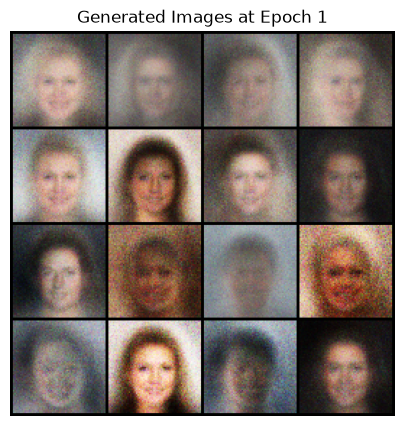

Checkpoint saved after epoch 1
Epoch [2/5], Step [0/1583], D Loss: 0.4429, G Loss: 1.8705, D(x): 0.68, D(G(z)): 0.21
Epoch [2/5], Step [50/1583], D Loss: 0.4716, G Loss: 2.3334, D(x): 0.72, D(G(z)): 0.31
Epoch [2/5], Step [100/1583], D Loss: 0.4784, G Loss: 2.1131, D(x): 0.66, D(G(z)): 0.25
Epoch [2/5], Step [150/1583], D Loss: 0.4548, G Loss: 2.0575, D(x): 0.65, D(G(z)): 0.23
Epoch [2/5], Step [200/1583], D Loss: 0.3987, G Loss: 2.3091, D(x): 0.69, D(G(z)): 0.19
Epoch [2/5], Step [250/1583], D Loss: 0.5714, G Loss: 1.4174, D(x): 0.56, D(G(z)): 0.25
Epoch [2/5], Step [300/1583], D Loss: 0.5190, G Loss: 2.6254, D(x): 0.65, D(G(z)): 0.34
Epoch [2/5], Step [350/1583], D Loss: 0.4436, G Loss: 2.0694, D(x): 0.63, D(G(z)): 0.21
Epoch [2/5], Step [400/1583], D Loss: 0.4181, G Loss: 2.4020, D(x): 0.74, D(G(z)): 0.26
Epoch [2/5], Step [450/1583], D Loss: 0.4394, G Loss: 2.1170, D(x): 0.69, D(G(z)): 0.25
Epoch [2/5], Step [500/1583], D Loss: 0.4391, G Loss: 1.9541, D(x): 0.66, D(G(z)): 0.23
Epoc

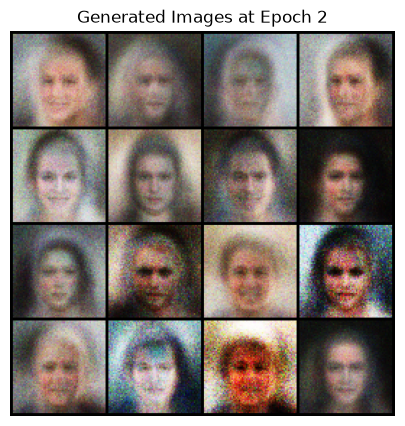

Checkpoint saved after epoch 2
Epoch [3/5], Step [0/1583], D Loss: 0.5000, G Loss: 1.4940, D(x): 0.58, D(G(z)): 0.26
Epoch [3/5], Step [50/1583], D Loss: 0.4598, G Loss: 2.1993, D(x): 0.70, D(G(z)): 0.29
Epoch [3/5], Step [100/1583], D Loss: 0.5024, G Loss: 2.5305, D(x): 0.69, D(G(z)): 0.30
Epoch [3/5], Step [150/1583], D Loss: 0.5108, G Loss: 1.6470, D(x): 0.60, D(G(z)): 0.23
Epoch [3/5], Step [200/1583], D Loss: 0.5079, G Loss: 2.0347, D(x): 0.67, D(G(z)): 0.31
Epoch [3/5], Step [250/1583], D Loss: 0.4642, G Loss: 1.9154, D(x): 0.64, D(G(z)): 0.25
Epoch [3/5], Step [300/1583], D Loss: 0.5068, G Loss: 2.2838, D(x): 0.67, D(G(z)): 0.31
Epoch [3/5], Step [350/1583], D Loss: 0.5271, G Loss: 2.0405, D(x): 0.68, D(G(z)): 0.35
Epoch [3/5], Step [400/1583], D Loss: 0.5234, G Loss: 1.9927, D(x): 0.63, D(G(z)): 0.30
Epoch [3/5], Step [450/1583], D Loss: 0.6061, G Loss: 2.4640, D(x): 0.74, D(G(z)): 0.44
Epoch [3/5], Step [500/1583], D Loss: 0.5200, G Loss: 1.7923, D(x): 0.62, D(G(z)): 0.29
Epoc

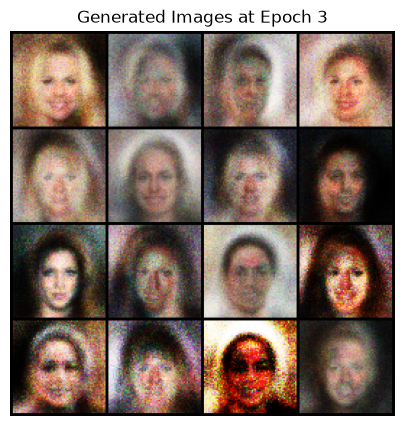

Checkpoint saved after epoch 3
Epoch [4/5], Step [0/1583], D Loss: 0.5388, G Loss: 1.7518, D(x): 0.60, D(G(z)): 0.30
Epoch [4/5], Step [50/1583], D Loss: 0.5419, G Loss: 1.8664, D(x): 0.63, D(G(z)): 0.34
Epoch [4/5], Step [100/1583], D Loss: 0.5672, G Loss: 1.5685, D(x): 0.53, D(G(z)): 0.25
Epoch [4/5], Step [150/1583], D Loss: 0.5412, G Loss: 1.6706, D(x): 0.56, D(G(z)): 0.28
Epoch [4/5], Step [200/1583], D Loss: 0.5735, G Loss: 1.7478, D(x): 0.57, D(G(z)): 0.33
Epoch [4/5], Step [250/1583], D Loss: 0.6065, G Loss: 1.5861, D(x): 0.55, D(G(z)): 0.35
Epoch [4/5], Step [300/1583], D Loss: 0.5484, G Loss: 1.5117, D(x): 0.60, D(G(z)): 0.30
Epoch [4/5], Step [350/1583], D Loss: 0.5972, G Loss: 1.5777, D(x): 0.49, D(G(z)): 0.25
Epoch [4/5], Step [400/1583], D Loss: 0.5816, G Loss: 1.5998, D(x): 0.64, D(G(z)): 0.38
Epoch [4/5], Step [450/1583], D Loss: 0.6702, G Loss: 1.8581, D(x): 0.64, D(G(z)): 0.47
Epoch [4/5], Step [500/1583], D Loss: 0.5144, G Loss: 1.7737, D(x): 0.58, D(G(z)): 0.24
Epoc

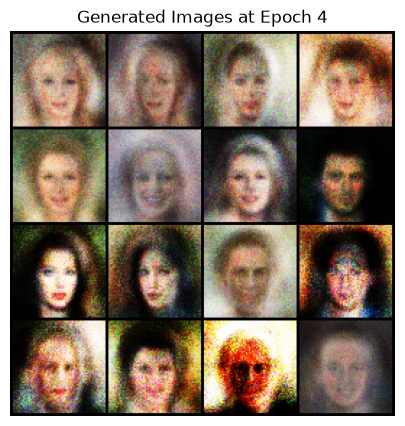

Checkpoint saved after epoch 4
Epoch [5/5], Step [0/1583], D Loss: 0.5879, G Loss: 1.5606, D(x): 0.57, D(G(z)): 0.35
Epoch [5/5], Step [50/1583], D Loss: 0.5665, G Loss: 1.4224, D(x): 0.56, D(G(z)): 0.31
Epoch [5/5], Step [100/1583], D Loss: 0.5576, G Loss: 1.6605, D(x): 0.65, D(G(z)): 0.39
Epoch [5/5], Step [150/1583], D Loss: 0.6044, G Loss: 1.5687, D(x): 0.55, D(G(z)): 0.33
Epoch [5/5], Step [200/1583], D Loss: 0.5848, G Loss: 1.9106, D(x): 0.63, D(G(z)): 0.37
Epoch [5/5], Step [250/1583], D Loss: 0.6162, G Loss: 1.5081, D(x): 0.55, D(G(z)): 0.35
Epoch [5/5], Step [300/1583], D Loss: 0.5608, G Loss: 1.6994, D(x): 0.58, D(G(z)): 0.32
Epoch [5/5], Step [350/1583], D Loss: 0.5329, G Loss: 1.7514, D(x): 0.61, D(G(z)): 0.33
Epoch [5/5], Step [400/1583], D Loss: 0.5971, G Loss: 1.5473, D(x): 0.55, D(G(z)): 0.33
Epoch [5/5], Step [450/1583], D Loss: 0.5370, G Loss: 1.5683, D(x): 0.53, D(G(z)): 0.25
Epoch [5/5], Step [500/1583], D Loss: 0.5470, G Loss: 1.6336, D(x): 0.56, D(G(z)): 0.30
Epoc

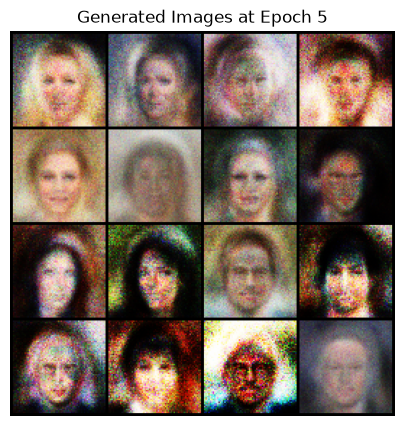

Checkpoint saved after epoch 5


In [21]:
train(discriminator, generator, dataLoader, start_epoch=start_epoch, epochs=5)

## Loss curves

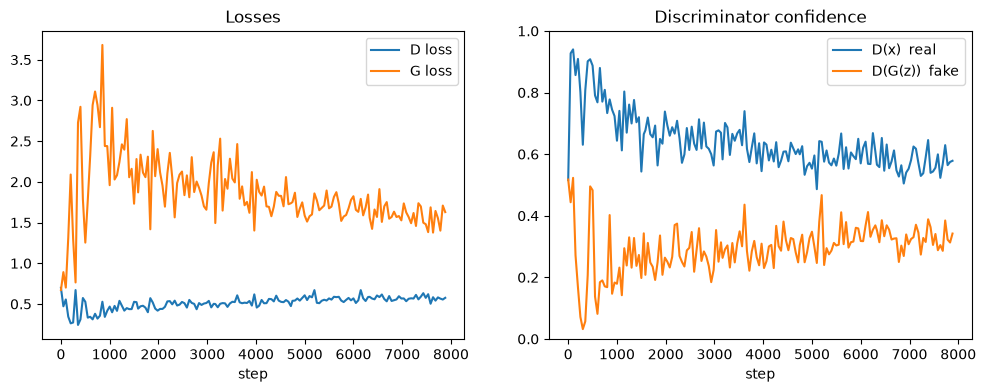

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history["step"], history["d_loss"], label="D loss")
ax1.plot(history["step"], history["g_loss"], label="G loss")
ax1.set_xlabel("step"); ax1.set_title("Losses"); ax1.legend()

ax2.plot(history["step"], history["d_real"], label="D(x)  real")
ax2.plot(history["step"], history["d_fake"], label="D(G(z))  fake")
ax2.set_xlabel("step"); ax2.set_ylim(0, 1); ax2.set_title("Discriminator confidence"); ax2.legend()

plt.show()